<a href="https://colab.research.google.com/github/imagra93/ML-course-labs/blob/main/notebooks/neural_networks/lab 11 - Fine-tuning ResNet pretrained vs scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab · Transfer learning: fine-tuning a pre-trained ResNet (satellite images)

You have a few hundred labelled images and a ResNet. There are two ways to start:

- **From scratch**: random weights. Everything the network knows has to be learned from your images.
- **Pre-trained**: weights learned on ImageNet (1.28 million photos, 1,000 classes), then adapted to your task. This is **transfer learning**.

Same architecture, same data, same training code; only the starting weights change. The images are deliberately *not* ImageNet-like: **EuroSAT**, satellite photos of 10 land-use classes (forest, river, highway, industrial area...). Will the knowledge transfer anyway?

This lab is also the template for most real image projects, and for the test at the end of the course: load a pre-trained network from `torchvision`, replace its last layer, feed it images with the right pre-processing, and train it with early stopping.

**Contents**

1. Setup and data
2. A pre-trained ResNet from `torchvision`
3. The data pipeline: `Dataset`, transforms, `DataLoader`
4. A training function with early stopping
5. Experiment 1: from scratch
6. Experiment 2: frozen backbone, new head (feature extraction)
7. Experiment 3: fine-tuning everything
8. Comparison on the test set
9. Where does it fail?
10. Using the model: save, load, predict
11. Summary and practical tips

Theory: Part B of the slides [CNNs, transfer learning, segmentation, detection](https://imagra93.github.io/ML-course-labs/slides/neural_networks/04_cnn.html) (ResNet, transfer learning). More experiments are in the **extended version** of this lab, linked at the end.

| Term | Meaning |
|---|---|
| backbone | every layer of the ResNet except the last one: it turns an image into 512 numbers, the **features** |
| head | the last linear layer, $512 \to 10$: it turns the features into class scores (logits) |

## 1. Setup and data

**Use a GPU** (in Colab: *Runtime → Change runtime type → T4 GPU*). With it the lab takes about 5 minutes; on a CPU it would take more than an hour.

EuroSAT (Helber et al., 2019) has 27,000 RGB images of $64 \times 64$ pixels. There is no official split, so we make a **stratified** one (every class keeps its share): 20% test, 10% validation, and the rest is a pool of labelled images. To reproduce the typical transfer-learning situation, we pretend that only **50 images per class** are labelled: a training set of 500 images.

In [1]:
import copy, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import EuroSAT
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.transforms import v2
from sklearn.model_selection import train_test_split
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

dataset = EuroSAT("~/.pytorch/EuroSAT", download=True)                 # ~90 MB, downloaded once
class_names = dataset.classes
images = torch.stack([v2.functional.pil_to_tensor(img) for img, _ in dataset])   # (27000, 3, 64, 64) uint8
labels = torch.tensor(dataset.targets)
y = labels.numpy()

rest, test_idx = train_test_split(np.arange(len(y)), test_size=0.20, stratify=y, random_state=0)
pool_idx, val_idx = train_test_split(rest, test_size=0.125, stratify=y[rest], random_state=0)   # 10% of the total
rng = np.random.default_rng(0)
train_idx = np.concatenate([rng.permutation(pool_idx[y[pool_idx] == c])[:50] for c in range(10)])   # 50 per class
print(f"{len(y)} images, {len(class_names)} classes:", ", ".join(class_names))
print(f"training {len(train_idx)}   validation {len(val_idx)}   test {len(test_idx)}")

device: cuda


27000 images, 10 classes: AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake
training 500   validation 2700   test 5400


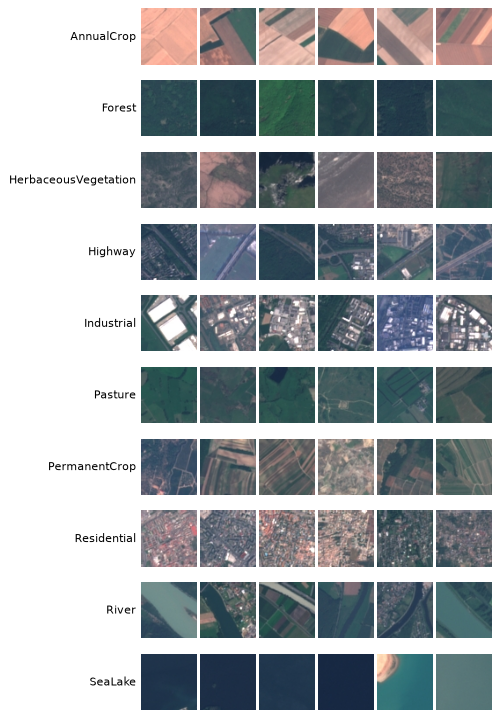

In [2]:
fig, axes = plt.subplots(10, 6, figsize=(6.5, 10.3))
for c, name in enumerate(class_names):
    for j, i in enumerate(train_idx[y[train_idx] == c][:6]):
        axes[c, j].imshow(images[i].permute(1, 2, 0)); axes[c, j].axis("off")
    axes[c, 0].text(-6, 32, name, ha="right", va="center", fontsize=9)
plt.subplots_adjust(left=0.3, wspace=0.05, hspace=0.05); plt.show()

Some classes are easy to tell apart (sea, forest, highway), others are not: *AnnualCrop*, *PermanentCrop*, *Pasture* and *HerbaceousVegetation* are all fields of different greens.

## 2. A pre-trained ResNet from `torchvision`

`torchvision.models` contains the classic architectures, each with optional pre-trained weights. `resnet18(weights=...)` builds a ResNet-18 and downloads its ImageNet weights (45 MB) the first time. The weights object also tells us **how the images were pre-processed** during pre-training:

In [3]:
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights)
print(weights.transforms())
print("\nlast layer:", model.fc)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

last layer: Linear(in_features=512, out_features=1000, bias=True)
parameters: 11,689,512


Two things to read in that output:

- **The pre-processing.** Pixels scaled to $[0, 1]$, then normalised with the ImageNet channel means and standard deviations. The pre-trained filters expect inputs on exactly that scale, so **we must use the same normalisation**. (We keep the normalisation but use $96 \times 96$ images instead of $224 \times 224$: our images are only $64 \times 64$, and smaller inputs train much faster.)
- **The head.** `fc` maps the 512 features to the 1,000 ImageNet classes. We replace it by a new `nn.Linear(512, 10)` for our 10 classes. The new head starts random in both experiments; only the backbone differs.

In [4]:
def make_resnet(pretrained):
    """ResNet-18 with a new 10-class head; ImageNet weights in the backbone if pretrained, random otherwise."""
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, len(class_names))     # 512 -> 10, random
    return model.to(device)

def trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_resnet(pretrained=True).fc)

Linear(in_features=512, out_features=10, bias=True)


## 3. The data pipeline: `Dataset`, transforms, `DataLoader`

The standard PyTorch pattern, the same as in the CNN lab and in the test:

- **Transforms** (`torchvision.transforms.v2`) turn one stored image into one network input. The **training** transform adds random **augmentation**. Satellite images have no "up": a forest seen from above is still a forest when flipped, so horizontal and vertical flips are safe. Validation and test images get the same resizing and normalisation, but no augmentation.
- A **`Dataset`** returns `(input, label)` for an index; here it applies the transform to one of the stored images.
- A **`DataLoader`** groups the examples into shuffled mini-batches, using `num_workers` background processes to prepare them.

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]     # ImageNet statistics, from weights.transforms()

train_tf = v2.Compose([
    v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(),        # augmentation: only for training
    v2.Resize(96),                                             # 64 x 64 -> 96 x 96
    v2.ToDtype(torch.float32, scale=True),                     # uint8 [0, 255] -> float [0, 1]
    v2.Normalize(MEAN, STD),                                   # the pre-training normalisation
])
eval_tf = v2.Compose([v2.Resize(96), v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)])

class EuroSATSubset(Dataset):
    """The images with indices idx, each passed through `transform` when it is requested."""
    def __init__(self, idx, transform):
        self.idx, self.transform = idx, transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        return self.transform(images[j]), labels[j]

loader_args = dict(num_workers=2, persistent_workers=True)
train_loader = DataLoader(EuroSATSubset(train_idx, train_tf), batch_size=64, shuffle=True, **loader_args)
val_loader = DataLoader(EuroSATSubset(val_idx, eval_tf), batch_size=256, **loader_args)
test_loader = DataLoader(EuroSATSubset(test_idx, eval_tf), batch_size=256, **loader_args)

xb, yb = next(iter(train_loader))
print("one training batch:", tuple(xb.shape), xb.dtype, "  labels:", tuple(yb.shape))
print("per-channel mean after normalisation:", xb.mean(dim=(0, 2, 3)).numpy().round(2))

one training batch: (64, 3, 96, 96) torch.float32   labels: (64,)
per-channel mean after normalisation: [-0.49 -0.26  0.06]


The means are not exactly 0, because satellite images are darker and less contrasted than ImageNet photos, but they are on the scale the pre-trained filters expect.

## 4. A training function with early stopping

The loop of the CNN lab, with both early-stopping techniques: keep the weights of the epoch with the lowest validation loss, and stop after `patience` epochs without improvement. Two changes:

- The **optimiser is passed in**, because each experiment trains different parameters with different learning rates.
- `frozen_bn=True` keeps the BatchNorm layers in evaluation mode. A frozen backbone should not change at all, but in `train` mode a BatchNorm layer keeps updating its running mean and variance with every batch, even when its weights are frozen.

In [6]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Mean loss and accuracy over a loader."""
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total += criterion(logits, yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)
    return total / n, correct / n

def fit(model, optimizer, epochs, patience, frozen_bn=False, verbose=True):
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}
    best_loss, best_state, best_epoch, t0 = float("inf"), None, 0, time.time()
    for epoch in range(epochs):
        model.train()
        if frozen_bn:                                    # keep the BatchNorm statistics of a frozen backbone fixed
            for m in model.modules():
                if isinstance(m, nn.BatchNorm2d): m.eval()
        tot, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            tot += loss.item() * len(yb); correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)
        vl, va = evaluate(model, val_loader)
        for k, v in zip(hist, (tot / n, correct / n, vl, va)): hist[k].append(v)
        if vl < best_loss:                               # early stopping 1: remember the best weights
            best_loss, best_state, best_epoch = vl, copy.deepcopy(model.state_dict()), epoch
        stop = epoch - best_epoch >= patience            # early stopping 2: patience
        if verbose and ((epoch + 1) % 5 == 0 or stop):
            print(f"epoch {epoch + 1:2d}  train loss {tot / n:.3f} acc {correct / n:.3f}   val loss {vl:.3f} acc {va:.3f}")
        if stop:
            print(f"no improvement for {patience} epochs: stop"); break
    model.load_state_dict(best_state)
    hist.update(best_epoch=best_epoch, time=time.time() - t0, trainable=trainable(model))
    print(f"-> restored epoch {best_epoch + 1}: val loss {best_loss:.3f}, val acc {hist['val_acc'][best_epoch]:.3f}"
          f"   ({hist['time']:.0f} s, {hist['trainable']:,} trainable parameters)")
    return hist

## 5. Experiment 1: from scratch

Random weights, all 11.2 million of them trained on 500 images, with Adam and the usual learning rate of $10^{-3}$. A network from scratch learns slowly and its validation curve is noisy, so we allow up to 60 epochs and a patience of 15.

In [7]:
torch.manual_seed(0)
net_scratch = make_resnet(pretrained=False)
optimizer = torch.optim.Adam(net_scratch.parameters(), lr=1e-3)
hist_scratch = fit(net_scratch, optimizer, epochs=60, patience=15)

epoch  5  train loss 1.020 acc 0.628   val loss 3.473 acc 0.279


epoch 10  train loss 0.830 acc 0.678   val loss 1.306 acc 0.551


epoch 15  train loss 0.641 acc 0.768   val loss 1.368 acc 0.579


epoch 20  train loss 0.476 acc 0.808   val loss 1.577 acc 0.561


epoch 25  train loss 0.528 acc 0.820   val loss 1.564 acc 0.601


epoch 30  train loss 0.376 acc 0.852   val loss 1.041 acc 0.693


epoch 35  train loss 0.394 acc 0.872   val loss 0.931 acc 0.733


epoch 40  train loss 0.349 acc 0.894   val loss 1.218 acc 0.668


epoch 43  train loss 0.415 acc 0.876   val loss 1.564 acc 0.605
no improvement for 15 epochs: stop
-> restored epoch 28: val loss 0.822, val acc 0.736   (41 s, 11,181,642 trainable parameters)


## 6. Experiment 2: frozen backbone, new head (feature extraction)

Start from the ImageNet weights, **freeze** the backbone (`requires_grad = False`: autograd computes no gradient for those weights, and the optimiser never sees them) and train only the new head: 5,130 parameters instead of 11.2 million. The backbone becomes a fixed feature extractor.

In [8]:
torch.manual_seed(0)
net_frozen = make_resnet(pretrained=True)
for p in net_frozen.parameters():
    p.requires_grad = False                     # freeze everything...
for p in net_frozen.fc.parameters():
    p.requires_grad = True                      # ...except the new head
optimizer = torch.optim.Adam(net_frozen.fc.parameters(), lr=1e-2)          # only 5,130 weights: a larger step is fine
hist_frozen = fit(net_frozen, optimizer, epochs=40, patience=5, frozen_bn=True)

epoch  5  train loss 0.207 acc 0.932   val loss 0.506 acc 0.858


epoch 10  train loss 0.095 acc 0.980   val loss 0.457 acc 0.868


epoch 11  train loss 0.086 acc 0.986   val loss 0.451 acc 0.866
no improvement for 5 epochs: stop
-> restored epoch 6: val loss 0.436, val acc 0.870   (9 s, 5,130 trainable parameters)


## 7. Experiment 3: fine-tuning everything

Now every layer is trained, but not at the same speed. The pre-trained layers are already good, so they get a **small learning rate** ($10^{-4}$); the new head starts random, so it gets a larger one ($10^{-3}$). An optimiser accepts **parameter groups**, each with its own learning rate.

In [9]:
torch.manual_seed(0)
net_ft = make_resnet(pretrained=True)
backbone = [p for name, p in net_ft.named_parameters() if not name.startswith("fc.")]
optimizer = torch.optim.Adam([
    {"params": backbone, "lr": 1e-4},                  # pre-trained layers: small steps
    {"params": net_ft.fc.parameters(), "lr": 1e-3},    # new head: larger steps
])
hist_ft = fit(net_ft, optimizer, epochs=40, patience=5)

epoch  5  train loss 0.138 acc 0.956   val loss 0.282 acc 0.910


epoch 10  train loss 0.034 acc 0.994   val loss 0.242 acc 0.921


epoch 15  train loss 0.016 acc 0.998   val loss 0.234 acc 0.921


epoch 20  train loss 0.007 acc 1.000   val loss 0.220 acc 0.925


epoch 25  train loss 0.005 acc 1.000   val loss 0.224 acc 0.931
no improvement for 5 epochs: stop
-> restored epoch 20: val loss 0.220, val acc 0.925   (22 s, 11,181,642 trainable parameters)


## 8. Comparison on the test set

The validation curves first, then each model evaluated once on the 5,400 test images.

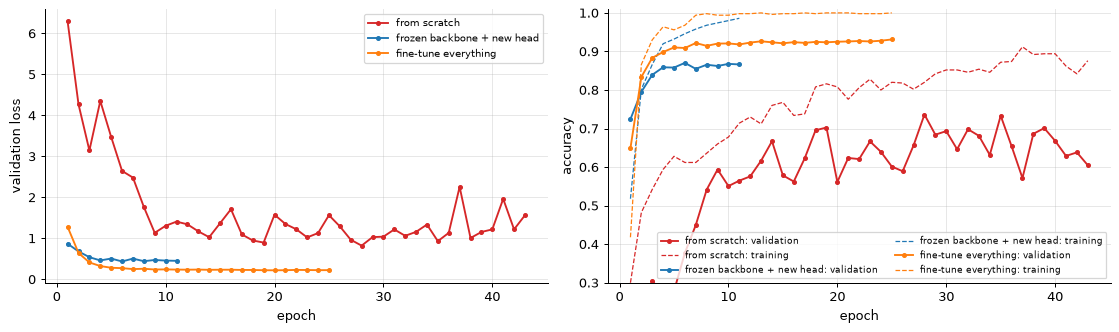

method                       trainable params  epochs   time  val acc  test acc


from scratch                       11,181,642      43    41s    0.736     0.721


frozen backbone + new head              5,130      11     9s    0.870     0.862


fine-tune everything               11,181,642      25    22s    0.925     0.930


In [10]:
runs = {"from scratch": (net_scratch, hist_scratch), "frozen backbone + new head": (net_frozen, hist_frozen),
        "fine-tune everything": (net_ft, hist_ft)}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, (_, h)), c in zip(runs.items(), ["C3", "C0", "C1"]):
    ep = np.arange(1, len(h["val_acc"]) + 1)
    axes[0].plot(ep, h["val_loss"], "o-", ms=3, color=c, label=name)
    axes[1].plot(ep, h["val_acc"], "o-", ms=3, color=c, label=f"{name}: validation")
    axes[1].plot(ep, h["train_acc"], "--", lw=1, color=c, label=f"{name}: training")
axes[0].set_ylabel("validation loss"); axes[1].set_ylabel("accuracy"); axes[1].set_ylim(0.3, 1.01)
for ax in axes: ax.set_xlabel("epoch")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

print(f"{'method':<28}{'trainable params':>17}{'epochs':>8}{'time':>7}{'val acc':>9}{'test acc':>10}")
for name, (net, h) in runs.items():
    print(f"{name:<28}{h['trainable']:>17,}{len(h['val_acc']):>8}{h['time']:>6.0f}s"
          f"{h['val_acc'][h['best_epoch']]:>9.3f}{evaluate(net, test_loader)[1]:>10.3f}")

**Reading the results.**
- **Pre-trained beats scratch by a wide margin**: 93% against 72% on the test set, with the same architecture, the same 500 images and the same training code, on images that look nothing like ImageNet.
- **The network from scratch is slow and unstable.** Its validation loss jumps from epoch to epoch, and its validation accuracy stays far below its training accuracy: 11 million weights cannot be learned well from 500 images. (The extended lab trains it with a learning-rate schedule and reaches about 81%, still far behind.)
- **A frozen backbone** reaches 86% while training only 5,130 weights, in a few seconds. The ImageNet features are useful as they are, but they were never adapted to satellite images.
- **Fine-tuning everything** with a small learning rate adapts those features and is the best of the three. It is above 90% validation accuracy after only 5 epochs.

## 9. Where does it fail?

The confusion matrix of the fine-tuned network on the test set, normalised by row: the diagonal is the recall of each class.

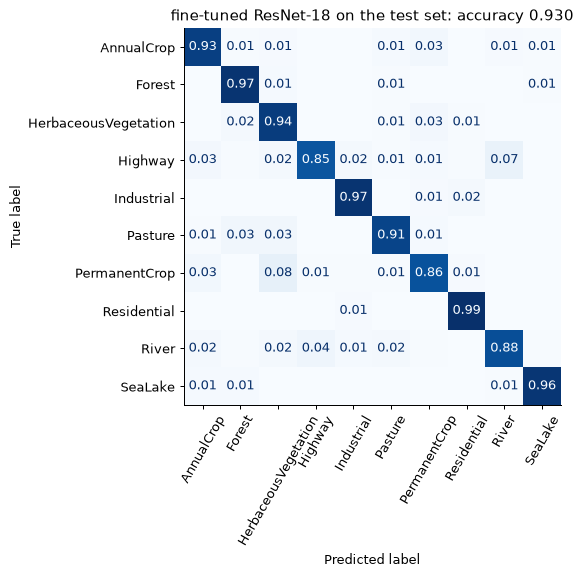

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

def predict(model, loader):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(device)).argmax(1).cpu() for xb, _ in loader]).numpy()

pred = predict(net_ft, test_loader)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_predictions(y[test_idx], pred, display_labels=class_names, normalize="true",
                                        values_format=".2f", cmap="Blues", xticks_rotation=60, colorbar=False, ax=ax)
for t in ax.texts:                                  # hide the many 0.00 cells
    if t.get_text() == "0.00": t.set_text("")
ax.grid(False); ax.set_title(f"fine-tuned ResNet-18 on the test set: accuracy {np.mean(pred == y[test_idx]):.3f}")
plt.tight_layout(); plt.show()

The errors are between classes that look alike from above: permanent crops taken for herbaceous vegetation, and highways taken for rivers and the other way round (both are long thin lines across a green background). Transfer learning does not remove the hard cases; it makes them rarer.

Below, 12 test images with the prediction (green: correct, red: wrong).

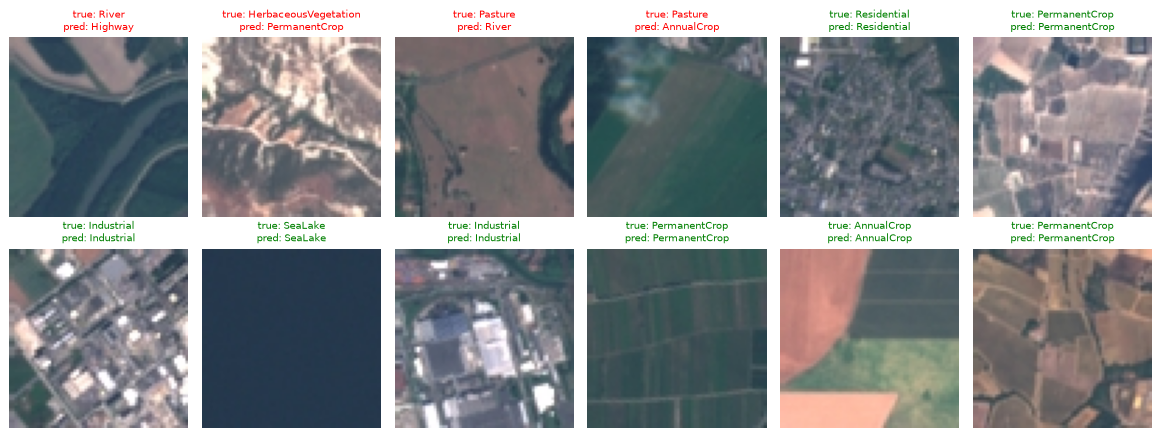

In [12]:
rng = np.random.default_rng(3)
show = np.concatenate([rng.choice(np.where(pred != y[test_idx])[0], 4, replace=False),     # 4 errors
                       rng.choice(np.where(pred == y[test_idx])[0], 8, replace=False)])    # 8 correct
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, k in zip(axes.ravel(), show):
    i = test_idx[k]
    ax.imshow(images[i].permute(1, 2, 0)); ax.axis("off")
    ok = pred[k] == y[i]
    ax.set_title(f"true: {class_names[y[i]]}\npred: {class_names[pred[k]]}", fontsize=8, color="green" if ok else "red")
plt.tight_layout(); plt.show()

## 10. Using the model: save, load, predict

A trained model is only useful if you can use it later. Save the **weights** (`state_dict`), not the whole Python object. To load them, build the same architecture first; it does not need the ImageNet weights, since they will be overwritten. To predict, apply the **evaluation** transform, add a batch dimension, and switch to `eval` mode.

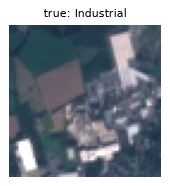

Industrial            0.989
Pasture               0.004
Highway               0.003


In [13]:
torch.save(net_ft.state_dict(), "eurosat_resnet18.pt")                 # about 45 MB

model = make_resnet(pretrained=False)                                    # same architecture, random weights
model.load_state_dict(torch.load("eurosat_resnet18.pt", map_location=device))
model.eval()

img = images[test_idx[7]]                                                # one image: (3, 64, 64) uint8
with torch.no_grad():
    probs = model(eval_tf(img).unsqueeze(0).to(device)).softmax(dim=1)[0]   # (1, 3, 96, 96) -> 10 probabilities
top = probs.topk(3)
plt.figure(figsize=(2.2, 2.2)); plt.imshow(img.permute(1, 2, 0)); plt.axis("off")
plt.title(f"true: {class_names[y[test_idx[7]]]}", fontsize=9); plt.show()
for p, c in zip(top.values.tolist(), top.indices.tolist()):
    print(f"{class_names[c]:<22}{p:.3f}")

## 11. Summary and practical tips

- A pre-trained network and a network from scratch have **the same architecture**; only the starting weights differ. ImageNet weights contain edges, colours and textures that are useful even for satellite images.
- **Feature extraction** (frozen backbone, new head) is fast and needs very few labels. **Fine-tuning** everything with a small learning rate adapts the features to the new images and is usually the best option once there are a few hundred labelled images.
- On 500 satellite images: 72% test accuracy from scratch, 86% with a frozen backbone, 93% with fine-tuning. The fewer labels you have, the larger the advantage of pre-training; the extended lab measures it from 50 to 6,000 training images.

**The transfer-learning recipe:**
1. Load a pre-trained model (`torchvision.models`) and **replace the head**: `model.fc = nn.Linear(model.fc.in_features, n_classes)`.
2. Pre-process the images **exactly as in pre-training**: the normalisation printed by `weights.transforms()`.
3. **Augment** the training images only, with transformations that cannot change the label.
4. **Baseline:** freeze the backbone and train the head. **Then fine-tune everything** with a learning rate about 10 times smaller for the backbone ($10^{-4}$ with Adam) than for the head.
5. Use **early stopping** on a validation set, and report the test set once.

**Pitfalls that fail silently** (no error, just a worse model):
- **A learning rate as large as for training from scratch** ($10^{-2}$) wipes out the pre-trained features in the first steps.
- **Forgetting the ImageNet normalisation**: the images look fine to you, but every activation is on the wrong scale.
- **A "frozen" backbone in `train` mode** still updates its BatchNorm statistics.
- **Forgetting `model.eval()`** at prediction time: BatchNorm then uses the statistics of the current batch, which for a single image is nonsense.

## Exercises

Try each one before opening the answer.

1. **Counting.** How many parameters does each strategy train? What fraction of the network does feature extraction train?
2. **A learning rate that is too large.** Fine-tune everything with a single learning rate of $10^{-2}$ for all layers (one parameter group). Compare with section 7 and with the network from scratch. What happened?
3. **Augmentation.** Which augmentations would you use for (a) photos of cats and dogs, (b) chest X-rays, (c) handwritten digits? Which would be *wrong*?
4. **Choosing a strategy.** What would you do with (a) 300 photos of two kinds of ants, (b) 3,000 chest X-rays, (c) 500,000 satellite images?

<details>
<summary><b>Answers</b></summary>

**1.** Head only: $512 \cdot 10 + 10 = 5{,}130$ parameters, 0.05% of the network. Fine-tuning and training from scratch: all 11,181,642. Feature extraction trains a tiny fraction of the weights and still gets most of the way there: the pre-trained features do the work.

**2.** The pre-trained network ends up *worse*, often worse than the network trained from scratch (the extended lab measures about 64% test accuracy). At the start the head is random, so the gradients flowing into the backbone are large and meaningless; with a large learning rate, the first steps overwrite the good features with noise, and 500 images are not enough to learn them again. Fine-tuning needs a learning rate 10 to 100 times smaller than training from scratch.

**3.** (a) Cats and dogs: horizontal flips, small rotations, crops, brightness changes; no vertical flips (animals are not upside down). (b) Chest X-rays: small rotations and shifts, brightness and contrast; no horizontal flip, which would move the heart to the other side and create anatomically impossible images. (c) Digits: small rotations and shifts; no flips (a mirrored 2 is not a 2, and 6 and 9 swap under a 180° rotation). Satellite images are the exception: they have no "up", so all flips and rotations are safe.

**4.** (a) 300 images of something close to ImageNet (ImageNet contains ants): a frozen backbone with a new head, maybe also fine-tuning the last block. (b) 3,000 images from a different domain: fine-tune everything with a small learning rate, and look for a model pre-trained on medical images if there is one. (c) 500,000 images: fine-tune everything; pre-training still speeds up training, and training from scratch becomes a serious option with that much data.

</details>

## Going further: the extended lab

The extended version of this lab uses the same data and adds:
- what an ImageNet network "sees" in a satellite image, and its first-layer filters before and after training;
- a baseline with **no CNN training at all**: pre-trained features + logistic regression;
- fine-tuning only the last block, with a learning-rate warm-up (one-cycle schedule);
- which weights move during fine-tuning, and the feature space visualised with t-SNE;
- **how many labels do you need?** Accuracy against training-set size, from 50 to 6,000 images;
- three ways to break a fine-tune (learning rate, normalisation, BatchNorm), measured; and six exercises.

<a href="https://colab.research.google.com/github/imagra93/ML-course-labs/blob/main/notebooks/neural_networks/lab 11 - Fine-tuning ResNet pretrained vs scratch - extended.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> [lab 11 - Fine-tuning ResNet pretrained vs scratch - extended.ipynb](lab%2011%20-%20Fine-tuning%20ResNet%20pretrained%20vs%20scratch%20-%20extended.ipynb)